# Comparacion de arquitecturas: ResNet50 y MobileNetV2

Clasificacion de plantas medicinales con el dataset Herbify.
Se usan las 57 especies que tienen al menos 50 imagenes, con el split ya guardado en `dataset/` (70% train, 15% validacion, 15% test, semilla 42).

| Rol | Arquitectura | Por que |
| --- | --- | --- |
| Modelo pesado | ResNet50 | Red residual de ImageNet, unos 23 millones de parametros |
| Modelo ligero | MobileNetV2 | Convoluciones separables, pensada para equipos con poca memoria |

Las dos redes comparten la misma entrada (224x224), la misma augmentacion, la misma cabeza de clasificacion y el mismo protocolo de entrenamiento en dos fases. Asi la diferencia de accuracy se puede atribuir a la arquitectura.

Ejecuta las celdas en orden, con el kernel del entorno `.venv` (TensorFlow + DirectML). En GPU el proceso completo puede tardar varias horas. Al terminar, este archivo queda con las curvas, las matrices y la tabla de comparacion: ese es el archivo para entregar.


## 1. Entorno y datos

Si `dataset/train` no existe, no sigas: ese split es el mismo que usa el otro integrante.


In [1]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

from pathlib import Path
import json
import time

import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import tensorflow as tf
from sklearn.metrics import classification_report, confusion_matrix

PROYECTO = Path.cwd()
DATASET = PROYECTO / "dataset"
SALIDA = PROYECTO / "resultados_comparacion"
SALIDA.mkdir(parents=True, exist_ok=True)

gpus = tf.config.list_physical_devices("GPU")
for gpu in gpus:
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError:
        pass

print("TensorFlow", tf.__version__)
print("GPU:", gpus or "no detectada")
for split in ("train", "val", "test"):
    if not (DATASET / split).is_dir():
        raise FileNotFoundError(f"Falta {DATASET / split}")


TensorFlow 2.10.1
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


## 2. Pipeline comun

La augmentacion solo corre en entrenamiento. Es la misma para las dos arquitecturas: giros, rotacion, zoom, desplazamiento, contraste y brillo.


Found 3408 files belonging to 57 classes.
Found 734 files belonging to 57 classes.
Found 761 files belonging to 57 classes.
Clases: 57


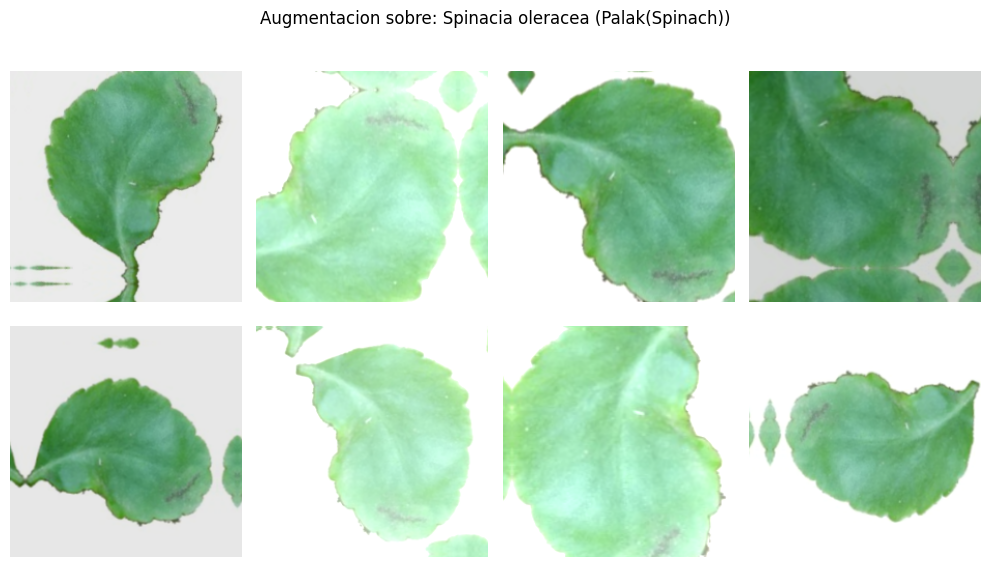

In [2]:
IMG = (224, 224)
BATCH = 16
SEMILLA = 42
EPOCHS_FASE1 = 20
EPOCHS_FASE2 = 15
tf.keras.utils.set_random_seed(SEMILLA)

AUTOTUNE = tf.data.AUTOTUNE

def hacer_augmentacion():
    return tf.keras.Sequential([
        tf.keras.layers.RandomFlip("horizontal_and_vertical"),
        tf.keras.layers.RandomRotation(0.25),
        tf.keras.layers.RandomZoom(0.25),
        tf.keras.layers.RandomTranslation(0.15, 0.15),
        tf.keras.layers.RandomContrast(0.3),
        tf.keras.layers.RandomBrightness(0.25, value_range=(0, 255)),
    ], name="augmentacion")

def cargar_datos(clave):
    def un_split(split, shuffle):
        ds = tf.keras.utils.image_dataset_from_directory(
            DATASET / split,
            image_size=IMG,
            batch_size=BATCH,
            shuffle=shuffle,
            seed=SEMILLA,
            label_mode="int",
        )
        nombres = list(ds.class_names)
        cache = SALIDA / "cache" / f"{clave}_{split}_b{BATCH}"
        cache.parent.mkdir(parents=True, exist_ok=True)
        ds = ds.cache(str(cache))
        if shuffle:
            ds = ds.shuffle(500, seed=SEMILLA)
        return ds.prefetch(AUTOTUNE), nombres

    train_ds, clases = un_split("train", True)
    val_ds, clases_val = un_split("val", False)
    test_ds, clases_test = un_split("test", False)
    if clases != clases_val or clases != clases_test:
        raise RuntimeError("Las clases de train, val y test no coinciden.")
    return train_ds, val_ds, test_ds, clases

train_prev, _, _, CLASES = cargar_datos("vista")
print("Clases:", len(CLASES))

lote, etiquetas = next(iter(train_prev))
vista = hacer_augmentacion()
plt.figure(figsize=(10, 6))
for i in range(8):
    plt.subplot(2, 4, i + 1)
    img = vista(tf.expand_dims(lote[0], 0), training=True)[0]
    plt.imshow(tf.cast(img, tf.uint8))
    plt.axis("off")
plt.suptitle(f"Augmentacion sobre: {CLASES[int(etiquetas[0])]}")
plt.tight_layout()
plt.show()


## 3. Entrenamiento en dos fases

Fase 1: la base de ImageNet queda congelada y solo aprende la cabeza (Adam 1e-3).
Fase 2: se descongelan las ultimas 40 capas con un learning rate bajo (Adam 1e-5) para no borrar lo aprendido en ImageNet.

Early stopping observa `val_accuracy` (paciencia 5) y restaura los mejores pesos. Si `val_loss` se estanca, el learning rate baja a la mitad.


In [16]:
def callbacks():
    return [
        tf.keras.callbacks.EarlyStopping(
            monitor="val_accuracy", patience=5, restore_best_weights=True
        ),
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss", factor=0.5, patience=3
        ),
    ]

def construir(num_clases, crear_base, preproceso, nombre):
    base = crear_base()
    base.trainable = False
    entradas = tf.keras.Input(shape=IMG + (3,))
    x = hacer_augmentacion()(entradas)
    x = preproceso(x)
    x = base(x, training=False)
    x = tf.keras.layers.GlobalAveragePooling2D()(x)
    x = tf.keras.layers.Dropout(0.4)(x)
    salidas = tf.keras.layers.Dense(num_clases, activation="softmax")(x)
    modelo = tf.keras.Model(entradas, salidas, name=nombre)
    return modelo, base

def curvas(hist1, hist2, titulo):
    acc = hist1.history["accuracy"] + hist2.history["accuracy"]
    vacc = hist1.history["val_accuracy"] + hist2.history["val_accuracy"]
    loss = hist1.history["loss"] + hist2.history["loss"]
    vloss = hist1.history["val_loss"] + hist2.history["val_loss"]
    corte = len(hist1.history["accuracy"])
    fig, ax = plt.subplots(1, 2, figsize=(13, 4))
    ax[0].plot(acc, label="train")
    ax[0].plot(vacc, label="val")
    ax[0].axvline(corte - 0.5, color="gray", linestyle="--", label="fine-tuning")
    ax[0].set_title("Accuracy")
    ax[0].set_xlabel("Epoca")
    ax[0].legend()
    ax[1].plot(loss, label="train")
    ax[1].plot(vloss, label="val")
    ax[1].axvline(corte - 0.5, color="gray", linestyle="--", label="fine-tuning")
    ax[1].set_title("Loss")
    ax[1].set_xlabel("Epoca")
    ax[1].legend()
    fig.suptitle(titulo)
    fig.tight_layout()
    fig.savefig(SALIDA / f"curvas_{titulo.lower()}.png", dpi=120)
    plt.show()
    return acc, vacc

def evaluar(modelo, test_ds, clases, titulo):
    perdida, accuracy = modelo.evaluate(test_ds, verbose=1)
    y_true = np.concatenate([y.numpy() for _, y in test_ds])
    y_prob = modelo.predict(test_ds, verbose=1)
    y_pred = y_prob.argmax(axis=1)
    top3 = float(np.mean(
        tf.keras.metrics.sparse_top_k_categorical_accuracy(y_true, y_prob, k=3).numpy()
    ))
    print(classification_report(y_true, y_pred, target_names=clases, digits=3))
    cm = confusion_matrix(y_true, y_pred)
    lado = max(12, min(28, 0.28 * len(clases)))
    plt.figure(figsize=(lado, lado * 0.8))
    sns.heatmap(cm, cmap="Blues", xticklabels=clases, yticklabels=clases, cbar=False)
    plt.xticks(fontsize=6, rotation=90)
    plt.yticks(fontsize=6)
    plt.xlabel("Predicho")
    plt.ylabel("Real")
    plt.title(f"Matriz de confusion - {titulo}")
    plt.tight_layout()
    plt.savefig(SALIDA / f"matriz_{titulo.lower()}.png", dpi=120)
    plt.show()
    return float(perdida), float(accuracy), top3, int(np.sum(y_true != y_pred)), int(len(y_true))

def _a_lista(valor):
    if isinstance(valor, tf.Tensor):
        return valor.numpy().tolist()
    if isinstance(valor, dict):
        return {clave: _a_lista(item) for clave, item in valor.items()}
    if isinstance(valor, (list, tuple)):
        return [_a_lista(item) for item in valor]
    return valor

def guardar_modelo(modelo, ruta):
    # EfficientNet guarda la media y la varianza como tensores.
    # TensorFlow 2.10 no puede escribirlos en un .h5 si no se pasan a lista.
    vistos = set()

    def recorrer(capa):
        clase = capa.__class__
        if clase not in vistos:
            vistos.add(clase)
            original = clase.get_config

            def get_config(self, _original=original):
                return _a_lista(_original(self))

            clase.get_config = get_config
        if hasattr(capa, "layers"):
            for sub in capa.layers:
                recorrer(sub)

    recorrer(modelo)
    modelo.save(ruta, include_optimizer=False)

def entrenar_arquitectura(clave, titulo, crear_base, preproceso):
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEMILLA)
    train_ds, val_ds, test_ds, clases = cargar_datos(clave)
    modelo, base = construir(len(clases), crear_base, preproceso, clave)
    modelo.compile(
        optimizer=tf.keras.optimizers.Adam(1e-3),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    print(f"\n{titulo} - fase 1: base congelada")
    modelo.summary()
    t0 = time.perf_counter()
    hist1 = modelo.fit(
        train_ds, validation_data=val_ds, epochs=EPOCHS_FASE1, callbacks=callbacks()
    )
    base.trainable = True
    for capa in base.layers[:-40]:
        capa.trainable = False
    modelo.compile(
        optimizer=tf.keras.optimizers.Adam(1e-5),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    print(f"\n{titulo} - fase 2: ultimas 40 capas")
    hist2 = modelo.fit(
        train_ds, validation_data=val_ds, epochs=EPOCHS_FASE2, callbacks=callbacks()
    )
    minutos = (time.perf_counter() - t0) / 60
    curvas(hist1, hist2, titulo)
    ruta = SALIDA / f"modelo_{clave}.h5"
    guardar_modelo(modelo, ruta)
    perdida, accuracy, top3, errores, n_test = evaluar(modelo, test_ds, clases, titulo)
    metricas = {
        "modelo": titulo,
        "accuracy_test": accuracy,
        "loss_test": perdida,
        "top3_accuracy_test": top3,
        "errores_test": errores,
        "imagenes_test": n_test,
        "parametros": int(modelo.count_params()),
        "minutos_entrenamiento": round(minutos, 1),
        "tamano_mb": round(ruta.stat().st_size / (1024 * 1024), 2),
        "batch": BATCH,
        "imagen": 224,
        "split": "70/15/15",
        "semilla": SEMILLA,
    }
    (SALIDA / f"metricas_{clave}.json").write_text(
        json.dumps(metricas, ensure_ascii=False, indent=2), encoding="utf-8"
    )
    (SALIDA / "clases.json").write_text(
        json.dumps(clases, ensure_ascii=False, indent=2), encoding="utf-8"
    )
    print(f"{titulo}: accuracy test {accuracy:.3f} | top-3 {top3:.3f} | {minutos:.1f} min")
    return metricas


3.1 modelo pesado EfficientNetB0

Found 3408 files belonging to 57 classes.
Found 734 files belonging to 57 classes.
Found 761 files belonging to 57 classes.

EfficientNetB0 - fase 1: base congelada
Model: "efficientnetb0"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_2 (InputLayer)        [(None, 224, 224, 3)]     0         
                                                                 
 augmentacion (Sequential)   (None, 224, 224, 3)       0         
                                                                 
 efficientnetb0 (Functional)  (None, 7, 7, 1280)       4049571   
                                                                 
 global_average_pooling2d (G  (None, 1280)             0         
 lobalAveragePooling2D)                                          
                                                                 
 dropout (Dropout)           (None, 1280)              0         
                   

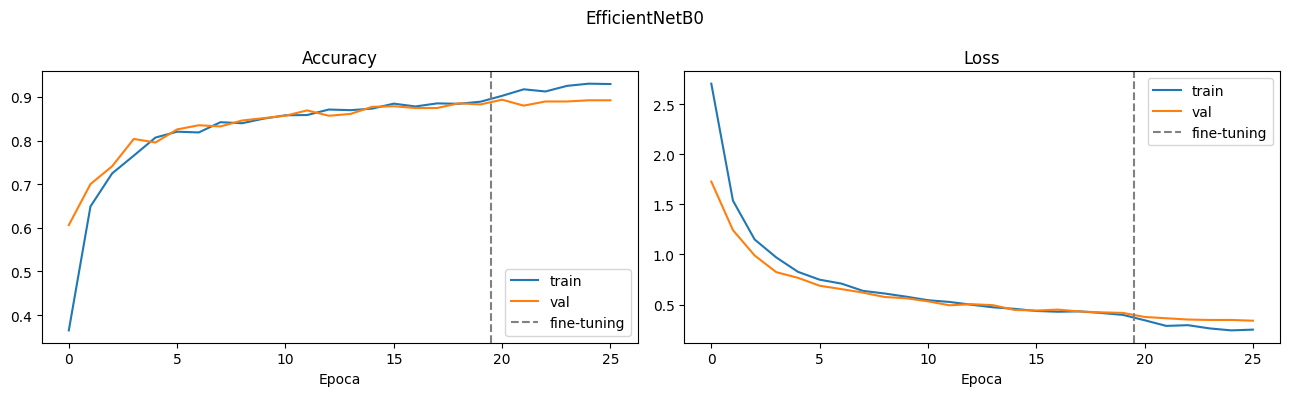

48/48 [==============================] - 3s 34ms/step
                                              precision    recall  f1-score   support

                         Allium cepa (Onion)      1.000     1.000     1.000        14
          Aloe barbadensis miller (Aloevera)      1.000     1.000     1.000        11
                     Alpinia Galanga (Rasna)      1.000     1.000     1.000         8
            Amaranthus Viridis (Arive-Dantu)      1.000     0.947     0.973        19
         Andrographis paniculata (Nelavembu)      0.889     0.727     0.800        11
                Annona squamosa (Seethapala)      0.700     0.778     0.737         9
        Artocarpus heterophyllus (Jackfruit)      0.786     0.647     0.710        17
                   Azadirachta indica (Neem)      0.909     0.909     0.909        11
                    Bacopa monnieri (Bhrami)      1.000     0.846     0.917        13
              Basella alba (Malabar Spinach)      0.926     1.000     0.962        25

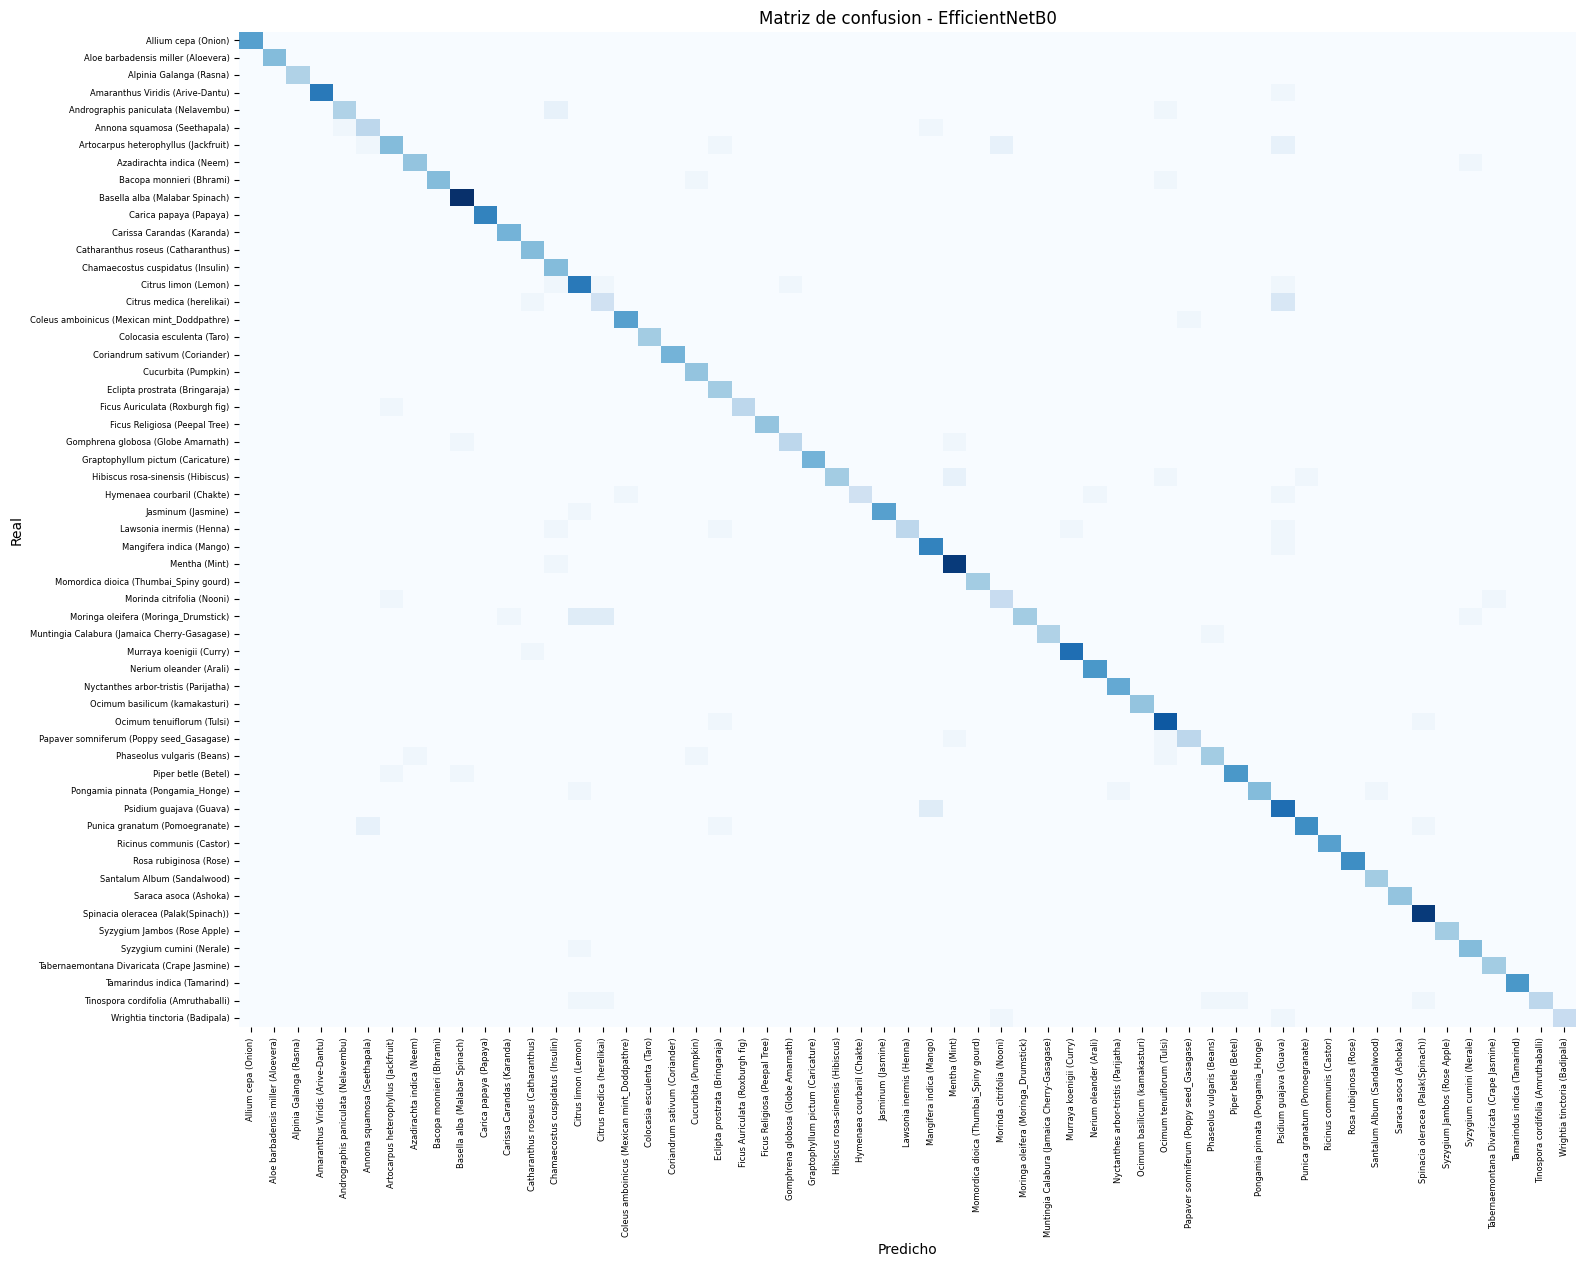

EfficientNetB0: accuracy test 0.894 | top-3 0.979 | 36.6 min


{'modelo': 'EfficientNetB0',
 'accuracy_test': 0.8935611844062805,
 'loss_test': 0.3720403015613556,
 'top3_accuracy_test': 0.9789750576019287,
 'errores_test': 81,
 'imagenes_test': 761,
 'parametros': 4122588,
 'minutos_entrenamiento': 36.6,
 'tamano_mb': 16.1,
 'batch': 16,
 'imagen': 224,
 'split': '70/15/15',
 'semilla': 42}

In [17]:
metricas_efficientnet = entrenar_arquitectura(
    "efficientnetb0",
    "EfficientNetB0",
    lambda: tf.keras.applications.EfficientNetB0(
        input_shape=IMG + (3,), include_top=False, weights="imagenet"
    ),
    tf.keras.applications.efficientnet.preprocess_input,
)
metricas_efficientnet

## 4. Modelo pesado: ResNet50

ResNet50 aprende funciones residuales: cada bloque suma la entrada a la salida de las convoluciones. Eso permite entrenar una red profunda sin que el gradiente se desvanezca. El preprocesamiento de esta red pasa la imagen a BGR y resta la media de ImageNet.


Found 3408 files belonging to 57 classes.
Found 734 files belonging to 57 classes.
Found 761 files belonging to 57 classes.
94765736/94765736 [==============================] - 9s 0us/step

ResNet50 - fase 1: base congelada
Model: "resnet50"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_2 (InputLayer)        [(None, 224, 224, 3)]     0         
                                                                 
 augmentacion (Sequential)   (None, 224, 224, 3)       0         
                                                                 
 tf.__operators__.getitem (S  (None, 224, 224, 3)      0         
 licingOpLambda)                                                 
                                                                 
 tf.nn.bias_add (TFOpLambda)  (None, 224, 224, 3)      0         
                                                                 
 resnet50 (Functional)       (No

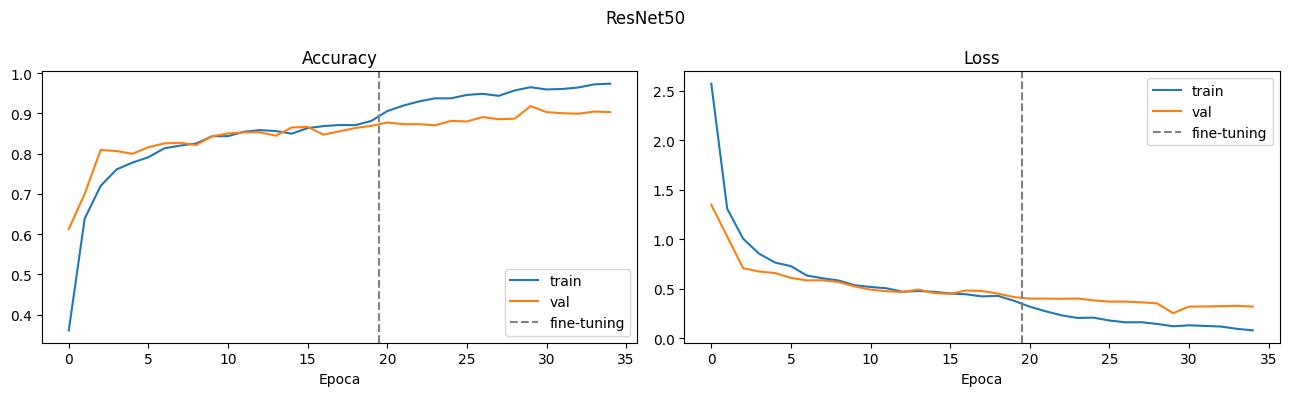

48/48 [==============================] - 2s 39ms/step
                                              precision    recall  f1-score   support

                         Allium cepa (Onion)      1.000     1.000     1.000        14
          Aloe barbadensis miller (Aloevera)      1.000     1.000     1.000        11
                     Alpinia Galanga (Rasna)      1.000     0.875     0.933         8
            Amaranthus Viridis (Arive-Dantu)      1.000     1.000     1.000        19
         Andrographis paniculata (Nelavembu)      0.727     0.727     0.727        11
                Annona squamosa (Seethapala)      0.750     1.000     0.857         9
        Artocarpus heterophyllus (Jackfruit)      1.000     0.765     0.867        17
                   Azadirachta indica (Neem)      1.000     0.909     0.952        11
                    Bacopa monnieri (Bhrami)      1.000     0.769     0.870        13
              Basella alba (Malabar Spinach)      0.880     0.880     0.880        25

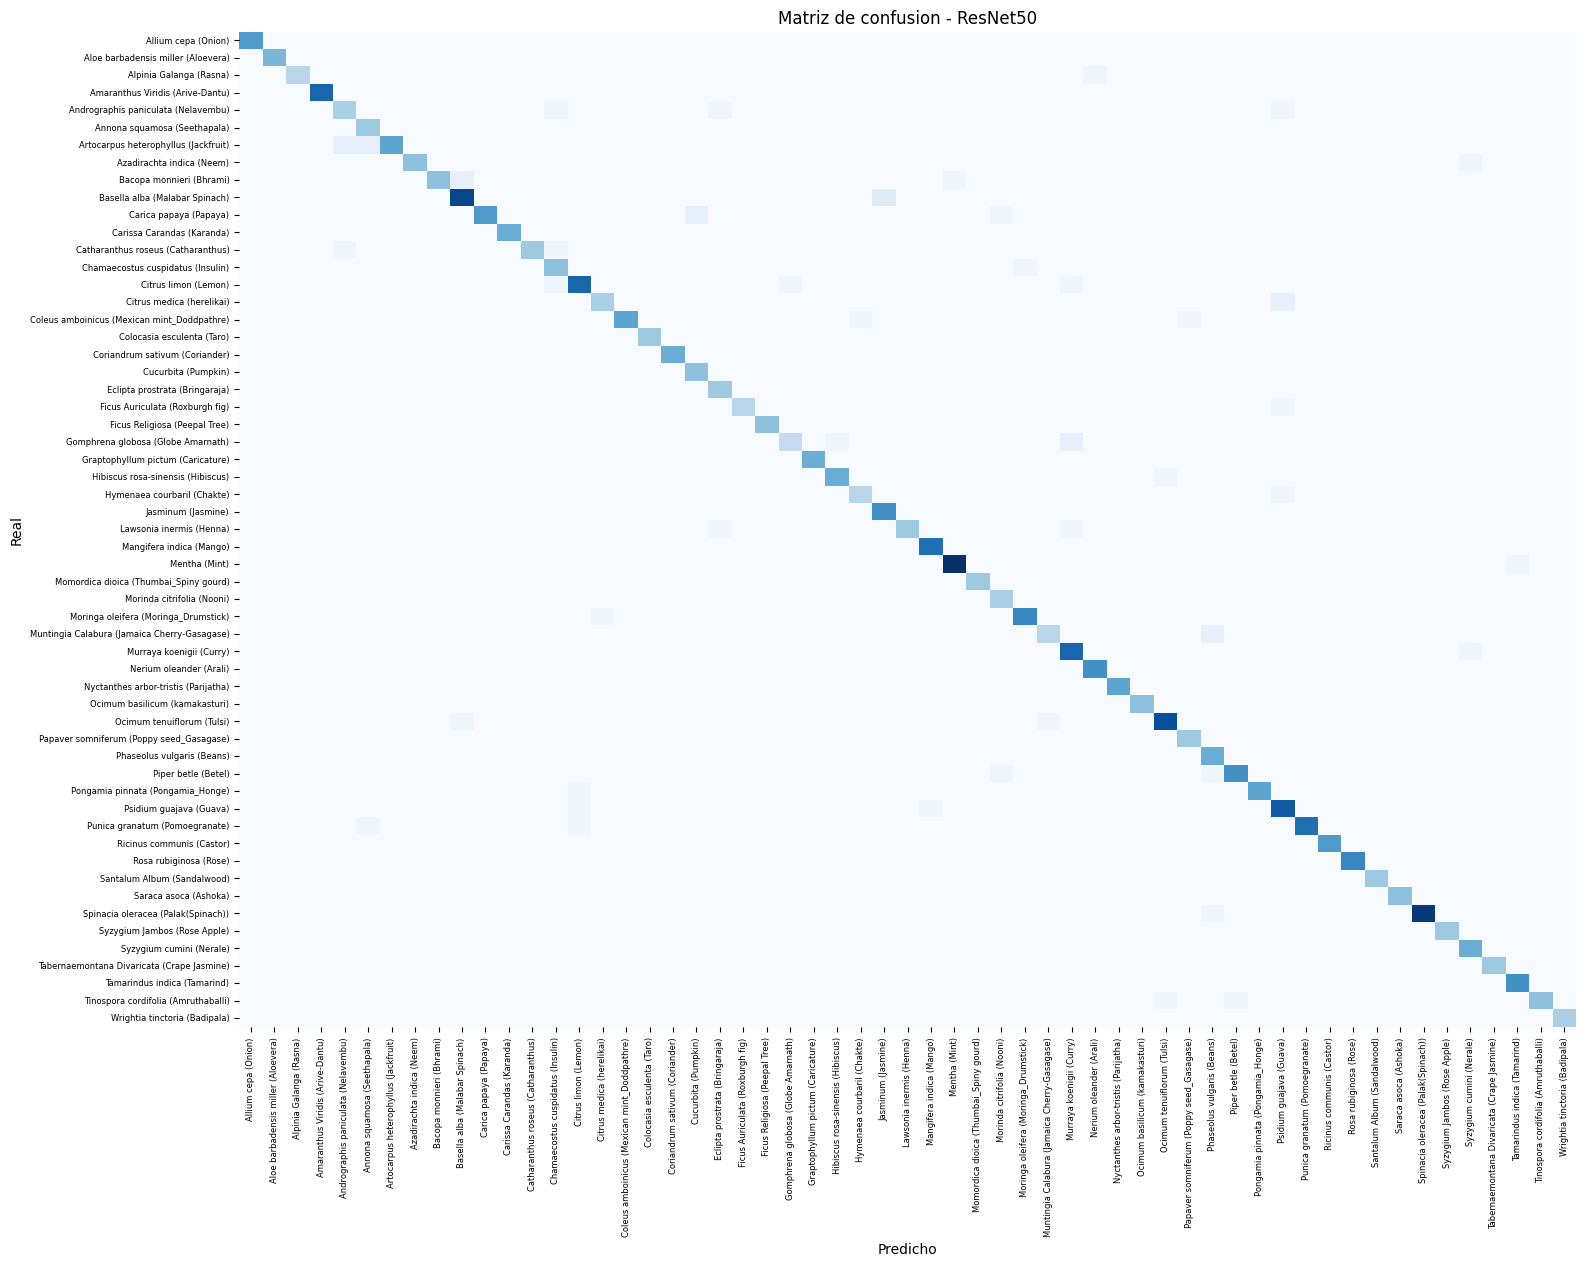

ResNet50: accuracy test 0.930 | top-3 0.987 | 40.8 min


{'modelo': 'ResNet50',
 'accuracy_test': 0.9303548336029053,
 'loss_test': 0.24372071027755737,
 'top3_accuracy_test': 0.9868593811988831,
 'errores_test': 53,
 'imagenes_test': 761,
 'parametros': 23704505,
 'minutos_entrenamiento': 40.8,
 'tamano_mb': 212.53,
 'batch': 16,
 'imagen': 224,
 'split': '70/15/15',
 'semilla': 42}

In [6]:
metricas_resnet = entrenar_arquitectura(
    "resnet50",
    "ResNet50",
    lambda: tf.keras.applications.ResNet50(
        input_shape=IMG + (3,), include_top=False, weights="imagenet"
    ),
    tf.keras.applications.resnet50.preprocess_input,
)
metricas_resnet


## 5. Modelo ligero: MobileNetV2

MobileNetV2 reemplaza la convolucion normal por convoluciones separables en profundidad y bloques residuales invertidos. Tiene muchos menos parametros que ResNet50, asi que entrena y predice con menos memoria. El preprocesamiento escala los pixeles al rango [-1, 1].


Found 3408 files belonging to 57 classes.
Found 734 files belonging to 57 classes.
Found 761 files belonging to 57 classes.

MobileNetV2 - fase 1: base congelada
Model: "mobilenetv2"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_2 (InputLayer)        [(None, 224, 224, 3)]     0         
                                                                 
 augmentacion (Sequential)   (None, 224, 224, 3)       0         
                                                                 
 tf.math.truediv (TFOpLambda  (None, 224, 224, 3)      0         
 )                                                               
                                                                 
 tf.math.subtract (TFOpLambd  (None, 224, 224, 3)      0         
 a)                                                              
                                                                 
 mobilenetv2_1.00_224 (Fu

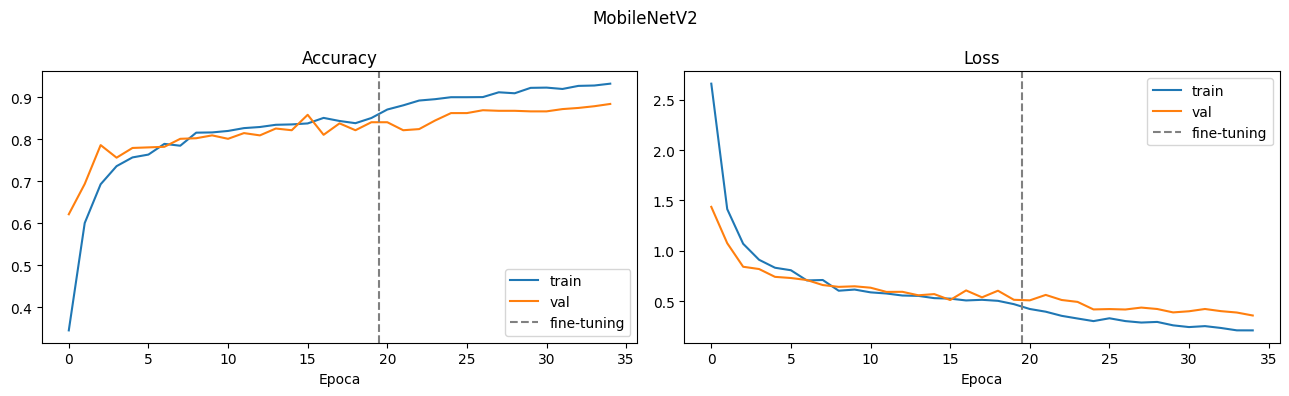

48/48 [==============================] - 2s 27ms/step
                                              precision    recall  f1-score   support

                         Allium cepa (Onion)      1.000     1.000     1.000        14
          Aloe barbadensis miller (Aloevera)      1.000     1.000     1.000        11
                     Alpinia Galanga (Rasna)      0.889     1.000     0.941         8
            Amaranthus Viridis (Arive-Dantu)      0.900     0.947     0.923        19
         Andrographis paniculata (Nelavembu)      0.727     0.727     0.727        11
                Annona squamosa (Seethapala)      0.889     0.889     0.889         9
        Artocarpus heterophyllus (Jackfruit)      0.875     0.824     0.848        17
                   Azadirachta indica (Neem)      0.769     0.909     0.833        11
                    Bacopa monnieri (Bhrami)      1.000     0.923     0.960        13
              Basella alba (Malabar Spinach)      0.880     0.880     0.880        25

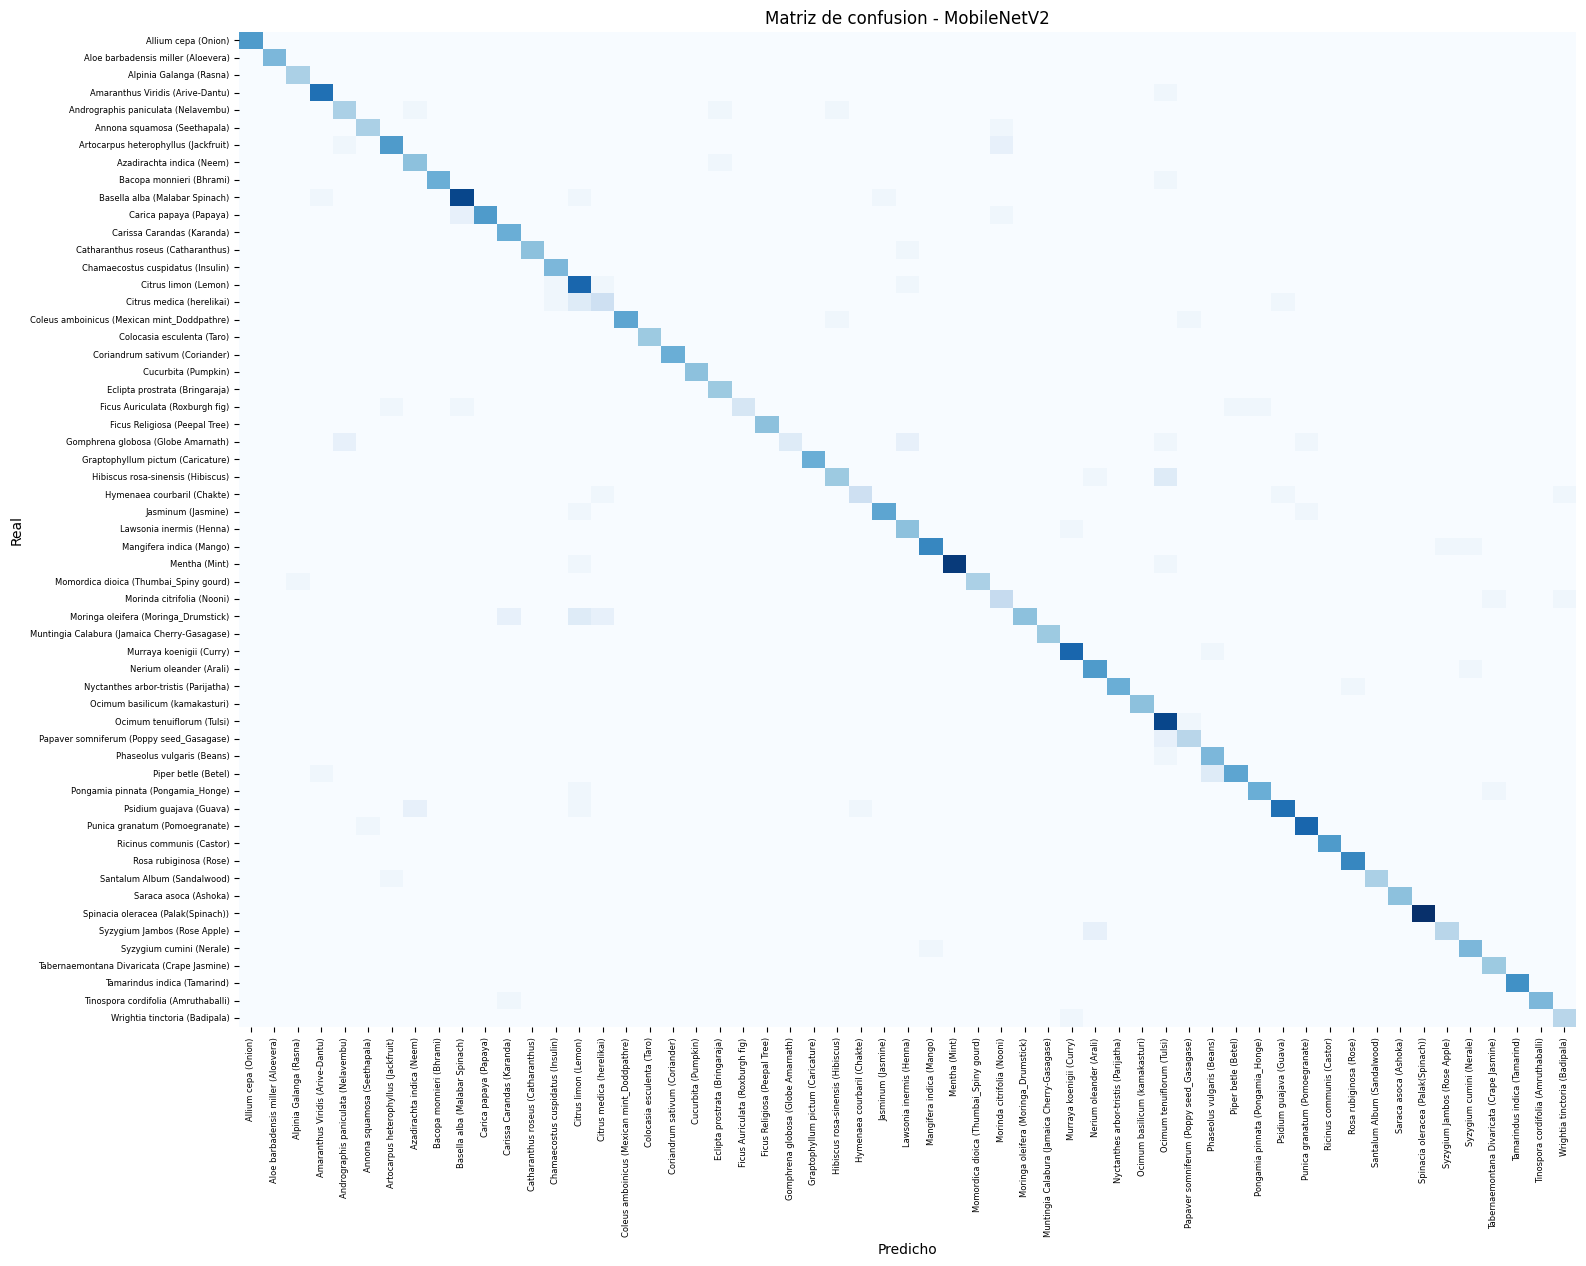

MobileNetV2: accuracy test 0.888 | top-3 0.967 | 42.8 min


{'modelo': 'MobileNetV2',
 'accuracy_test': 0.8883048892021179,
 'loss_test': 0.36479973793029785,
 'top3_accuracy_test': 0.96714848279953,
 'errores_test': 85,
 'imagenes_test': 761,
 'parametros': 2331001,
 'minutos_entrenamiento': 42.8,
 'tamano_mb': 22.68,
 'batch': 16,
 'imagen': 224,
 'split': '70/15/15',
 'semilla': 42}

In [8]:
metricas_mobilenet = entrenar_arquitectura(
    "mobilenetv2",
    "MobileNetV2",
    lambda: tf.keras.applications.MobileNetV2(
        input_shape=IMG + (3,), include_top=False, weights="imagenet"
    ),
    tf.keras.applications.mobilenet_v2.preprocess_input,
)
metricas_mobilenet


## 6. Comparacion

La metrica principal es el accuracy en el conjunto de test. Top-3 sirve como apoyo porque hay 57 especies parecidas. Parametros, peso del archivo y tiempo dicen el costo de cada arquitectura.

Esta celda junta ResNet50, EfficientNetB0 y MobileNetV2. Si acabas de terminar EfficientNetB0, vuelvela a ejecutar: lee las metricas guardadas y no reentrena las redes que ya terminaron.


modelo            accuracy     top-3    params M      MB     min
ResNet50             0.930     0.987       23.70   212.5    40.8
EfficientNetB0       0.894     0.979        4.12    16.1    36.6
MobileNetV2          0.888     0.967        2.33    22.7    42.8


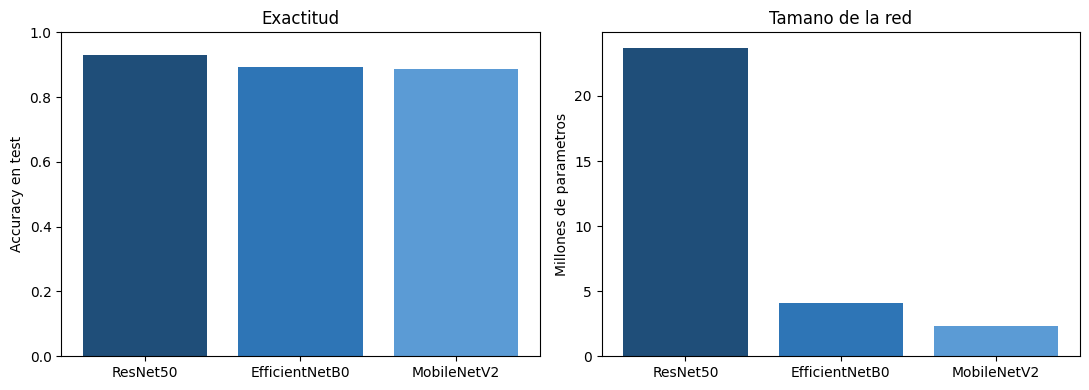

Tabla y grafica guardadas en d:\juandmm1233\NoElectivaIII\resultados_comparacion


In [18]:
def tomar_metricas(nombre_variable, archivo):
    if nombre_variable in globals() and isinstance(globals()[nombre_variable], dict):
        return globals()[nombre_variable]
    ruta = SALIDA / archivo
    if ruta.exists():
        return json.loads(ruta.read_text(encoding="utf-8"))
    return None

candidatos = [
    ("metricas_resnet", "metricas_resnet50.json"),
    ("metricas_efficientnet", "metricas_efficientnetb0.json"),
    ("metricas_mobilenet", "metricas_mobilenetv2.json"),
]
filas = []
for variable, archivo in candidatos:
    metricas = tomar_metricas(variable, archivo)
    if metricas is None:
        print(f"Todavia no esta {archivo}. Cuando ese entrenamiento termine, vuelve a correr esta celda.")
    else:
        filas.append(metricas)

print(f"{'modelo':<16}{'accuracy':>10}{'top-3':>10}{'params M':>12}{'MB':>8}{'min':>8}")
for m in filas:
    print(
        f"{m['modelo']:<16}{m['accuracy_test']:>10.3f}{m['top3_accuracy_test']:>10.3f}"
        f"{m['parametros'] / 1e6:>12.2f}{m['tamano_mb']:>8.1f}{m['minutos_entrenamiento']:>8.1f}"
    )

ruta_companero = PROYECTO / "para_companero" / "resultados" / "metricas_mobilenetv2.json"
if ruta_companero.exists():
    del_companero = json.loads(ruta_companero.read_text(encoding="utf-8"))
    print(
        f"\nMobileNetV2 del companero: accuracy {del_companero['accuracy_test']:.3f}. "
        "Es la misma red ligera, entrenada en el otro PC. Sirve para comprobar el resultado, "
        "no como una arquitectura distinta en la grafica."
    )

colores = ["#1f4e79", "#2e75b6", "#5b9bd5"]
nombres = [m["modelo"] for m in filas]
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].bar(nombres, [m["accuracy_test"] for m in filas], color=colores[:len(filas)])
ax[0].set_ylim(0, 1)
ax[0].set_ylabel("Accuracy en test")
ax[0].set_title("Exactitud")
ax[1].bar(nombres, [m["parametros"] / 1e6 for m in filas], color=colores[:len(filas)])
ax[1].set_ylabel("Millones de parametros")
ax[1].set_title("Tamano de la red")
fig.tight_layout()
fig.savefig(SALIDA / "comparacion.png", dpi=120)
plt.show()

(SALIDA / "comparacion.json").write_text(
    json.dumps(filas, ensure_ascii=False, indent=2), encoding="utf-8"
)
print("Tabla y grafica guardadas en", SALIDA)


Todavia no esta metricas_efficientnetb0.json. Cuando ese entrenamiento termine, vuelve a correr esta celda.
modelo            accuracy     top-3    params M      MB     min
ResNet50             0.930     0.987       23.70   212.5    40.8
MobileNetV2          0.888     0.967        2.33    22.7    42.8


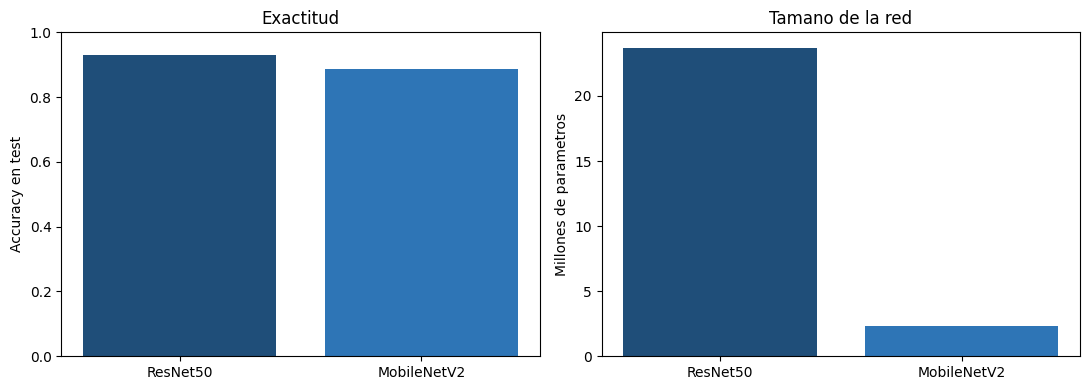

Tabla y grafica guardadas en d:\juandmm1233\NoElectivaIII\resultados_comparacion


In [14]:
def tomar_metricas(nombre_variable, archivo):
    if nombre_variable in globals() and isinstance(globals()[nombre_variable], dict):
        return globals()[nombre_variable]
    ruta = SALIDA / archivo
    if ruta.exists():
        return json.loads(ruta.read_text(encoding="utf-8"))
    return None

candidatos = [
    ("metricas_resnet", "metricas_resnet50.json"),
    ("metricas_efficientnet", "metricas_efficientnetb0.json"),
    ("metricas_mobilenet", "metricas_mobilenetv2.json"),
]
filas = []
for variable, archivo in candidatos:
    metricas = tomar_metricas(variable, archivo)
    if metricas is None:
        print(f"Todavia no esta {archivo}. Cuando ese entrenamiento termine, vuelve a correr esta celda.")
    else:
        filas.append(metricas)

print(f"{'modelo':<16}{'accuracy':>10}{'top-3':>10}{'params M':>12}{'MB':>8}{'min':>8}")
for m in filas:
    print(
        f"{m['modelo']:<16}{m['accuracy_test']:>10.3f}{m['top3_accuracy_test']:>10.3f}"
        f"{m['parametros'] / 1e6:>12.2f}{m['tamano_mb']:>8.1f}{m['minutos_entrenamiento']:>8.1f}"
    )

ruta_companero = PROYECTO / "para_companero" / "resultados" / "metricas_mobilenetv2.json"
if ruta_companero.exists():
    del_companero = json.loads(ruta_companero.read_text(encoding="utf-8"))
    print(
        f"\nMobileNetV2 del companero: accuracy {del_companero['accuracy_test']:.3f}. "
        "Es la misma red ligera, entrenada en el otro PC. Sirve para comprobar el resultado, "
        "no como una arquitectura distinta en la grafica."
    )

colores = ["#1f4e79", "#2e75b6", "#5b9bd5"]
nombres = [m["modelo"] for m in filas]
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].bar(nombres, [m["accuracy_test"] for m in filas], color=colores[:len(filas)])
ax[0].set_ylim(0, 1)
ax[0].set_ylabel("Accuracy en test")
ax[0].set_title("Exactitud")
ax[1].bar(nombres, [m["parametros"] / 1e6 for m in filas], color=colores[:len(filas)])
ax[1].set_ylabel("Millones de parametros")
ax[1].set_title("Tamano de la red")
fig.tight_layout()
fig.savefig(SALIDA / "comparacion.png", dpi=120)
plt.show()

(SALIDA / "comparacion.json").write_text(
    json.dumps(filas, ensure_ascii=False, indent=2), encoding="utf-8"
)
print("Tabla y grafica guardadas en", SALIDA)

## 7. Transfer learning de ResNet50 hacia MobileNetV3

ResNet50 y MobileNetV3 no comparten capas, asi que los pesos del primero no se pueden copiar dentro del segundo. Lo que si se transfiere es el conocimiento: ResNet50, ya entrenado en estas 57 especies, actua como profesor. MobileNetV3Small empieza con los pesos de ImageNet y aprende cada foto con dos senales:

1. La etiqueta real de la especie.
2. Las probabilidades que ResNet50 asigna a las 57 clases. Asi el modelo ligero imita las dudas del modelo pesado, no solo el acierto final.

Esta celda se ejecuta sola. No hace falta volver a entrenar ResNet50: carga `resultados_comparacion/modelo_resnet50.h5`.


In [ ]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

from pathlib import Path
import json
import time

import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import tensorflow as tf
from sklearn.metrics import classification_report, confusion_matrix

PROYECTO = Path.cwd()
if not (PROYECTO / "dataset").is_dir():
    PROYECTO = Path(r"D:\juandmm1233\NoElectivaIII")
DATASET = PROYECTO / "dataset"
SALIDA = PROYECTO / "resultados_comparacion"
IMG = (224, 224)
BATCH = 16
SEMILLA = 42
AUTOTUNE = tf.data.AUTOTUNE
tf.keras.utils.set_random_seed(SEMILLA)

gpus = tf.config.list_physical_devices("GPU")
for gpu in gpus:
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError:
        pass
print("TensorFlow", tf.__version__)
print("GPU:", gpus or "no detectada")

def hacer_augmentacion():
    return tf.keras.Sequential([
        tf.keras.layers.RandomFlip("horizontal_and_vertical"),
        tf.keras.layers.RandomRotation(0.25),
        tf.keras.layers.RandomZoom(0.25),
        tf.keras.layers.RandomTranslation(0.15, 0.15),
        tf.keras.layers.RandomContrast(0.3),
        tf.keras.layers.RandomBrightness(0.25, value_range=(0, 255)),
    ], name="augmentacion")

def cargar_datos(clave):
    def un_split(split, shuffle):
        ds = tf.keras.utils.image_dataset_from_directory(
            DATASET / split,
            image_size=IMG,
            batch_size=BATCH,
            shuffle=shuffle,
            seed=SEMILLA,
            label_mode="int",
        )
        nombres = list(ds.class_names)
        cache = SALIDA / "cache" / f"{clave}_{split}_b{BATCH}"
        cache.parent.mkdir(parents=True, exist_ok=True)
        ds = ds.cache(str(cache))
        if shuffle:
            ds = ds.shuffle(500, seed=SEMILLA)
        return ds.prefetch(AUTOTUNE), nombres

    train_ds, clases = un_split("train", True)
    val_ds, clases_val = un_split("val", False)
    test_ds, clases_test = un_split("test", False)
    if clases != clases_val or clases != clases_test:
        raise RuntimeError("Las clases de train, val y test no coinciden.")
    return train_ds, val_ds, test_ds, clases

def evaluar(modelo, test_ds, clases, titulo):
    perdida, accuracy = modelo.evaluate(test_ds, verbose=1)
    y_true = np.concatenate([y.numpy() for _, y in test_ds])
    y_prob = modelo.predict(test_ds, verbose=1)
    y_pred = y_prob.argmax(axis=1)
    top3 = float(np.mean(
        tf.keras.metrics.sparse_top_k_categorical_accuracy(y_true, y_prob, k=3).numpy()
    ))
    print(classification_report(y_true, y_pred, target_names=clases, digits=3))
    cm = confusion_matrix(y_true, y_pred)
    lado = max(12, min(28, 0.28 * len(clases)))
    plt.figure(figsize=(lado, lado * 0.8))
    sns.heatmap(cm, cmap="Blues", xticklabels=clases, yticklabels=clases, cbar=False)
    plt.xticks(fontsize=6, rotation=90)
    plt.yticks(fontsize=6)
    plt.xlabel("Predicho")
    plt.ylabel("Real")
    plt.title(f"Matriz de confusion - {titulo}")
    plt.tight_layout()
    plt.savefig(SALIDA / f"matriz_{titulo.lower()}.png", dpi=120)
    plt.show()
    return float(perdida), float(accuracy), top3, int(np.sum(y_true != y_pred)), int(len(y_true))

TEMPERATURA = 4.0
PESO_ETIQUETA = 0.5
EPOCHS_V3_FASE1 = 15
EPOCHS_V3_FASE2 = 10

profesor = tf.keras.models.load_model(SALIDA / "modelo_resnet50.h5", compile=False)
profesor.trainable = False
print("Profesor cargado: ResNet50,", profesor.count_params(), "parametros")

def crear_mobilenetv3(num_clases):
    base = tf.keras.applications.MobileNetV3Small(
        input_shape=IMG + (3,),
        include_top=False,
        weights="imagenet",
        include_preprocessing=True,
    )
    base.trainable = False
    entradas = tf.keras.Input(shape=IMG + (3,))
    x = hacer_augmentacion()(entradas)
    # El preprocesamiento ya va dentro de MobileNetV3. No hay que escalar otra vez.
    x = base(x, training=False)
    x = tf.keras.layers.GlobalAveragePooling2D()(x)
    x = tf.keras.layers.Dropout(0.4)(x)
    salidas = tf.keras.layers.Dense(num_clases, activation="softmax")(x)
    modelo = tf.keras.Model(entradas, salidas, name="mobilenetv3_desde_resnet50")
    return modelo, base

def perdida_transferencia(etiquetas, pred_estudiante, pred_profesor):
    dura = tf.keras.losses.sparse_categorical_crossentropy(etiquetas, pred_estudiante)
    blanda_profesor = tf.nn.softmax(tf.math.log(pred_profesor + 1e-8) / TEMPERATURA)
    blanda_estudiante = tf.nn.softmax(tf.math.log(pred_estudiante + 1e-8) / TEMPERATURA)
    blanda = tf.keras.losses.kl_divergence(blanda_profesor, blanda_estudiante) * (TEMPERATURA ** 2)
    return PESO_ETIQUETA * tf.reduce_mean(dura) + (1.0 - PESO_ETIQUETA) * tf.reduce_mean(blanda)

def exactitud(modelo, dataset):
    aciertos = 0
    total = 0
    for imagenes, etiquetas in dataset:
        pred = modelo(imagenes, training=False)
        clases_pred = tf.argmax(pred, axis=1, output_type=etiquetas.dtype)
        aciertos += int(tf.reduce_sum(tf.cast(clases_pred == etiquetas, tf.int32)))
        total += int(etiquetas.shape[0])
    return aciertos / max(total, 1)

def entrenar_fase(modelo, train_ds, val_ds, epochs, optimizador, titulo):
    mejor = -1.0
    espera = 0
    pesos = modelo.get_weights()
    historia = {"loss": [], "val_accuracy": []}
    for epoca in range(1, epochs + 1):
        perdidas = []
        for imagenes, etiquetas in train_ds:
            with tf.GradientTape() as cinta:
                pred_profesor = profesor(imagenes, training=False)
                pred_estudiante = modelo(imagenes, training=True)
                perdida = perdida_transferencia(etiquetas, pred_estudiante, pred_profesor)
            gradientes = cinta.gradient(perdida, modelo.trainable_variables)
            optimizador.apply_gradients(zip(gradientes, modelo.trainable_variables))
            perdidas.append(float(perdida))
        val_acc = exactitud(modelo, val_ds)
        loss_media = float(np.mean(perdidas))
        historia["loss"].append(loss_media)
        historia["val_accuracy"].append(val_acc)
        print(f"{titulo} epoca {epoca}/{epochs}  loss {loss_media:.4f}  val_accuracy {val_acc:.4f}")
        if val_acc > mejor:
            mejor = val_acc
            espera = 0
            pesos = modelo.get_weights()
        else:
            espera += 1
            if espera >= 4:
                print("Early stopping")
                break
    modelo.set_weights(pesos)
    return historia

train_v3, val_v3, test_v3, clases_v3 = cargar_datos("mobilenetv3")
estudiante, base_v3 = crear_mobilenetv3(len(clases_v3))
estudiante.summary()

t0 = time.perf_counter()
print("\nFase 1: MobileNetV3 congelado, aprende la cabeza con ResNet50")
hist_v3_1 = entrenar_fase(
    estudiante, train_v3, val_v3, EPOCHS_V3_FASE1,
    tf.keras.optimizers.Adam(1e-3), "Fase 1",
)

base_v3.trainable = True
for capa in base_v3.layers[:-40]:
    capa.trainable = False
print("\nFase 2: ultimas 40 capas de MobileNetV3, con learning rate bajo")
hist_v3_2 = entrenar_fase(
    estudiante, train_v3, val_v3, EPOCHS_V3_FASE2,
    tf.keras.optimizers.Adam(1e-5), "Fase 2",
)
minutos_v3 = (time.perf_counter() - t0) / 60

ruta_v3 = SALIDA / "modelo_mobilenetv3_desde_resnet50.h5"
if "guardar_modelo" in globals():
    guardar_modelo(estudiante, ruta_v3)
else:
    estudiante.save(ruta_v3, include_optimizer=False)

perdida_v3, accuracy_v3, top3_v3, errores_v3, n_test_v3 = evaluar(
    estudiante, test_v3, clases_v3, "MobileNetV3Small"
)
metricas_resnet_previas = json.loads((SALIDA / "metricas_resnet50.json").read_text(encoding="utf-8"))
metricas_v3 = {
    "modelo": "MobileNetV3Small desde ResNet50",
    "profesor": "ResNet50",
    "accuracy_test": accuracy_v3,
    "loss_test": perdida_v3,
    "top3_accuracy_test": top3_v3,
    "errores_test": errores_v3,
    "imagenes_test": n_test_v3,
    "parametros": int(estudiante.count_params()),
    "minutos_entrenamiento": round(minutos_v3, 1),
    "tamano_mb": round(ruta_v3.stat().st_size / (1024 * 1024), 2),
    "temperatura": TEMPERATURA,
    "peso_etiqueta": PESO_ETIQUETA,
    "accuracy_profesor": metricas_resnet_previas["accuracy_test"],
}
(SALIDA / "metricas_mobilenetv3_desde_resnet50.json").write_text(
    json.dumps(metricas_v3, ensure_ascii=False, indent=2), encoding="utf-8"
)

print(f"\nResNet50 profesor: accuracy test {metricas_resnet_previas['accuracy_test']:.3f}")
print(f"MobileNetV3 alumno: accuracy test {accuracy_v3:.3f} | top-3 {top3_v3:.3f} | {minutos_v3:.1f} min")
metricas_v3


TensorFlow 2.10.1
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]
Profesor cargado: ResNet50, 23704505 parametros
Found 3408 files belonging to 57 classes.
Found 734 files belonging to 57 classes.
Found 761 files belonging to 57 classes.
4334752/4334752 [==============================] - 1s 0us/step
Model: "mobilenetv3_desde_resnet50"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_2 (InputLayer)        [(None, 224, 224, 3)]     0         
                                                                 
 augmentacion (Sequential)   (None, 224, 224, 3)       0         
                                                                 
 MobilenetV3small (Functiona  (None, 7, 7, 576)        939120    
 l)                                                              
                                             